Exploring a graph.

In [1]:
import requests, readline, sys, json
import numpy
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn

from query import *
from summary import *


vertexQ is a query to get all vertex labels:

In [2]:
vertexQ

'g.V().label().groupCount()'

getQuery gets the query results, and printResp prints a response

In [3]:
printResp(getQuery(vertexQ))


{'MemoryObject': '13502', 'Event': '365320', 'FileObject': '63916', 'Principal': '41', 'Subject': '4024', 'NetFlowObject': '1178'}


getGroupCountQuery runs a query and converts the resulting dictionary to a groupCount

In [4]:
getGroupCountQuery(vertexQ)

[{'Event': 365320,
  'FileObject': 63916,
  'MemoryObject': 13502,
  'NetFlowObject': 1178,
  'Principal': 41,
  'Subject': 4024}]

getVertices collects the counts and number of incoming and outgoing edge labels for each vertex label.  For example:

In [5]:
vertices = getVertexSummary()
print (vertices)

Vertex types/counts:
{'MemoryObject': {'count': 13502, 'in': {'predicateObject': 23456}, 'out': {}}, 'Event': {'count': 365320, 'in': {}, 'out': {'predicateObject2': 16767, 'subject': 365320, 'predicateObject': 362146}}, 'FileObject': {'count': 63916, 'in': {'predicateObject2': 16767, 'subject': 4, 'predicateObject': 224947}, 'out': {}}, 'Principal': {'count': 41, 'in': {'localPrincipal': 4024, 'predicateObject': 16}, 'out': {}}, 'Subject': {'count': 4024, 'in': {'parentSubject': 4024, 'subject': 365316, 'predicateObject': 1738}, 'out': {'localPrincipal': 4024, 'parentSubject': 4024}}, 'NetFlowObject': {'count': 1178, 'in': {'predicateObject': 111989}, 'out': {}}}


Likewise, getEdges collects the counts of edge labels and the number of vertex labels on the source and target of each edge.

In [6]:
edges = getEdgeSummary()
print (edges)

Edge types/counts:
{'predicateObject2': {'count': 16767, 'in': {'FileObject': 16767}, 'out': {'Event': 16767}}, 'localPrincipal': {'count': 4024, 'in': {'Principal': 4024}, 'out': {'Subject': 4024}}, 'parentSubject': {'count': 4024, 'in': {'Subject': 4024}, 'out': {'Subject': 4024}}, 'subject': {'count': 365320, 'in': {'FileObject': 4, 'Subject': 365316}, 'out': {'Event': 365320}}, 'predicateObject': {'count': 362146, 'in': {'MemoryObject': 23456, 'FileObject': 224947, 'NetFlowObject': 111989, 'Subject': 1738, 'Principal': 16}, 'out': {'Event': 362146}}}


Hmm.  Not very readable.  Let's try to do better.  printSummary takes a dictionary in one of the above forms and prints out the results in a more structured way.

In [7]:
printSummary(vertices)

{predicateObject[23456]}
 -> 
MemoryObject[13502]
 -> 
{}

{}
 -> 
Event[365320]
 -> 
{predicateObject2[16767],
subject[365320],
predicateObject[362146]}

{predicateObject2[16767],
subject[4],
predicateObject[224947]}
 -> 
FileObject[63916]
 -> 
{}

{localPrincipal[4024],
predicateObject[16]}
 -> 
Principal[41]
 -> 
{}

{parentSubject[4024],
subject[365316],
predicateObject[1738]}
 -> 
Subject[4024]
 -> 
{localPrincipal[4024],
parentSubject[4024]}

{predicateObject[111989]}
 -> 
NetFlowObject[1178]
 -> 
{}



How about for edges?

In [8]:
printSummary(edges)

{FileObject[16767]}
 -> 
predicateObject2[16767]
 -> 
{Event[16767]}

{Principal[4024]}
 -> 
localPrincipal[4024]
 -> 
{Subject[4024]}

{Subject[4024]}
 -> 
parentSubject[4024]
 -> 
{Subject[4024]}

{FileObject[4],
Subject[365316]}
 -> 
subject[365320]
 -> 
{Event[365320]}

{MemoryObject[23456],
FileObject[224947],
NetFlowObject[111989],
Subject[1738],
Principal[16]}
 -> 
predicateObject[362146]
 -> 
{Event[362146]}



Now let's build and visualize a (bipartite) graph.  Nodes will represent either node or edge labels, and edges represent that a node can have an in-edge or out-edge with a given label (or vice versa).

In [9]:
G = nx.DiGraph()


In [10]:
G.add_nodes_from(vertices,bipartite=0)
G.add_nodes_from(edges,bipartite=1)

In [11]:
for v in vertices.keys():
    for e in vertices[v]['in'].keys():
        G.add_edge(e,v)
    for e in vertices[v]['out'].keys():
        G.add_edge(v,e)

In [12]:
nx.is_bipartite(G)

True

In [13]:
from networkx.algorithms import bipartite
bottom_nodes, top_nodes = bipartite.sets(G)
bottom_nodes,top_nodes

({'Event',
  'FileObject',
  'MemoryObject',
  'NetFlowObject',
  'Principal',
  'Subject'},
 {'localPrincipal',
  'parentSubject',
  'predicateObject',
  'predicateObject2',
  'subject'})

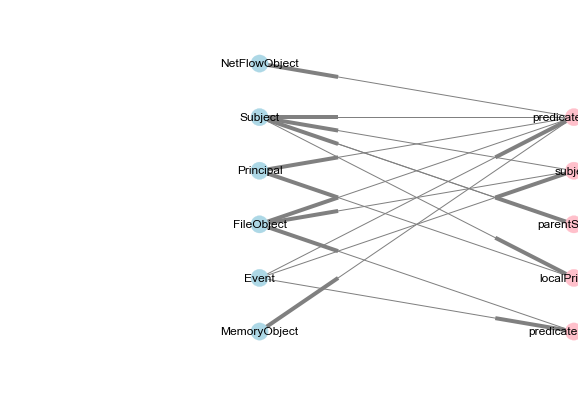

In [14]:
def showBiGraph(G):
    colors = ['lightblue' if d['bipartite']==0 else 'pink' for x,d in G.nodes(data=True)]
    positions = {}
    i = 1
    j = 1
    for x,d in G.nodes(data=True):
        if d['bipartite'] == 0:
            positions[x] = (3,i)
            i = i + 1
        else:
            positions[x] = (7,j)
            j = j + 1
    height = max(i,j)
    fig = plt.figure(figsize=(10,height))
    plt.gca().set_axis_off()   
    plt.gca().set_xlim([-0.05, height+0.05])    # add a little space around the plot
    plt.gca().set_ylim([-0.05, height+0.05])

    nx.draw_networkx(G,pos=positions,
                   with_labels=True,node_color=colors,edge_color='gray')

    _ = plt.show()

showBiGraph(G)

Consider the edge labels into and out of each node type and abstract them as +, *, 1, or ?

In [15]:
summarizeIncidences('Event')

{'in': {},
 'out': {'predicateObject': '?', 'predicateObject2': '?', 'subject': '1'}}

In [16]:

schema = inferSchema(vertices.keys())
schema

{'Event': {'in': {},
  'out': {'predicateObject': '?', 'predicateObject2': '?', 'subject': '1'}},
 'FileObject': {'in': {'predicateObject': '*',
   'predicateObject2': '*',
   'subject': '?'},
  'out': {}},
 'MemoryObject': {'in': {'predicateObject': '+'}, 'out': {}},
 'NetFlowObject': {'in': {'predicateObject': '+'}, 'out': {}},
 'Principal': {'in': {'localPrincipal': '*', 'predicateObject': '*'},
  'out': {}},
 'Subject': {'in': {'parentSubject': '*',
   'predicateObject': '?',
   'subject': '*'},
  'out': {'localPrincipal': '1', 'parentSubject': '1'}}}

A _rigid path_ is a path that follows only edges with multiplicity <= 1.  Edges can be traversed in either direction but should not be traversed twice.  Rigid paths are useful for exploring because it does no harm to follow them.

In [17]:
def multLeq1(edges):
    return {label for label in edges.keys() if edges[label]== '1' or edges[label] == '?'}

def schemaMultLeq1(schema):
    return {label : {'in': multLeq1(schema[label]['in']), 'out':multLeq1(schema[label]['out'])}
             for label in schema.keys()}
            
schemaMultLeq1(schema)
            

{'Event': {'in': set(),
  'out': {'predicateObject', 'predicateObject2', 'subject'}},
 'FileObject': {'in': {'subject'}, 'out': set()},
 'MemoryObject': {'in': set(), 'out': set()},
 'NetFlowObject': {'in': set(), 'out': set()},
 'Principal': {'in': set(), 'out': set()},
 'Subject': {'in': {'predicateObject'},
  'out': {'localPrincipal', 'parentSubject'}}}